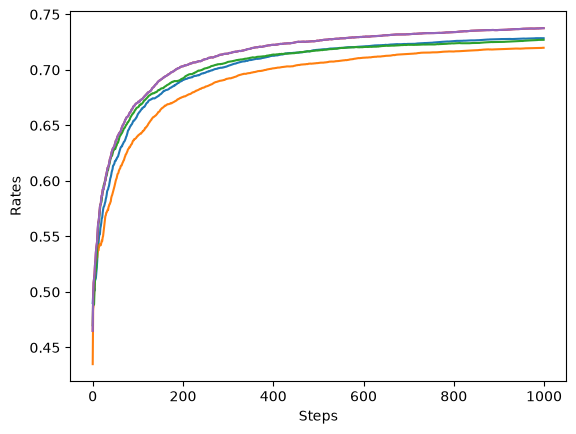

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from bandit import Bandit, Agent


runs = 200
steps = 1000
#epsilon = 0.1
epsilon_values = [0.1, 0.2, 0.5, 0.8]  # 다양한 epsilon 값

for epsilon in epsilon_values:
    all_rates = np.zeros((runs, steps))  # (200, 1000) 형상 배열
    for run in range(runs):  # 200번 실험
        bandit = Bandit()
        epsilon = np.random.choice(epsilon_values)
        agent = Agent(epsilon)
        total_reward = 0
        rates = []

        for step in range(steps):
            action = agent.get_action()
            reward = bandit.play(action)
            agent.update(action, reward)
            total_reward += reward
            rates.append(total_reward / (step + 1))

        all_rates[run] = rates  # 보상 결과 기록

    avg_rates = np.average(all_rates, axis=0)  # 각 단계의 평균 저장
    plt.plot(avg_rates, label=f'epsilon = {epsilon}')


# [그림 1-16] 단계별 승률(200번 실험 후 평균)
plt.ylabel('Rates')
plt.xlabel('Steps')
plt.plot(avg_rates)
plt.show()